- https://en.wikipedia.org/wiki/Law_of_total_variance
- https://openreview.net/pdf?id=1Jv6b0Zq3qi

- Statement:

$$
\mathbb{V}_{p(y|x,D)}[y]=\mathbb{E}_{p(y|x,\theta)}[\mathbb{V}_{p(\theta|D)}(y)] + \mathbb{V}_{p(y|x,\theta)}[\mathbb{E}_{p(\theta|D)}(y)]
$$

- Proof:

$$
\begin{split}\mathbb{V}_{p(y|x, D)}[y] = \underset{①}{\mathbb{E}_{p(y|x, D)}[y^{2}]} - \underset{②}{(\mathbb{E}_{p(y|x, D)}[y])^{2}}\end{split}
$$


$①=\mathbb{E}_{p(y|x, D)}[y^{2}] = \mathbb{E}_{p(\theta|D)}[\mathbb{E}_{p(y|x, \theta)}[y^{2}]]=\mathbb{E}_{p(\theta|D)}[\mathbb{V}_{p(y|x, \theta)}[y] + (\mathbb{E}_{p(y|x, \theta)}[y])^{2}]$

$②=(\mathbb{E}_{p(y|x, D)}[y])^{2} = (\mathbb{E}_{p(\theta|D)}[\mathbb{E}_{p(y|x, \theta)}[y]])^{2}$


$$
\begin{split}\therefore(① - ②)&=\mathbb{E}_{p(\theta|D)}[\mathbb{V}_{p(y|x, \theta)}[y] + (\mathbb{E}_{p(y|x, \theta)}[y])^{2}]-(\mathbb{E}_{p(\theta|D)}[\mathbb{E}_{p(y|x, \theta)}[y]])^{2} \\ &= \mathbb{E}_{p(\theta|D)}[\mathbb{V}_{p(y|x, \theta)}[y]] +  \mathbb{E}_{p(\theta|D)}[(\mathbb{E}_{p(y|x, \theta)}[y])^{2}] - (\mathbb{E}_{p(\theta|D)}[\mathbb{E}_{p(y|x, \theta)}[y]])^{2} \\ &= \mathbb{E}_{p(\theta|D)}[\mathbb{V}_{p(y|x, \theta)}[y]] + \mathbb{V}_{p(\theta|D)}[\mathbb{E}_{p(y|x, \theta)}[y]] \end{split}
$$

In [ ]:
import math
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

In [ ]:
# function for generating mean and variance
def gen_parameters(noise=0.01, seed=0):
    
    np.random.seed(seed)
    
    mean = np.random.rand(9, 9)
    
    figure = np.array([
        [1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 4, 1, 1, 1, 4, 1, 1],
        [1, 4, 0, 4, 1, 4, 0, 4, 1],
        [4, 0, 0, 0, 4, 0, 0, 0, 4],
        [1, 4, 0, 0, 0, 0, 0, 4, 1],
        [1, 1, 4, 0, 0, 0, 4, 1, 1],
        [1, 1, 1, 4, 0, 4, 1, 1, 1],
        [1, 1, 1, 1, 4, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1]
    ])

    var = figure * noise
    
    return mean, var

True data uncertainty (variance). The white region will not contain any traing data.


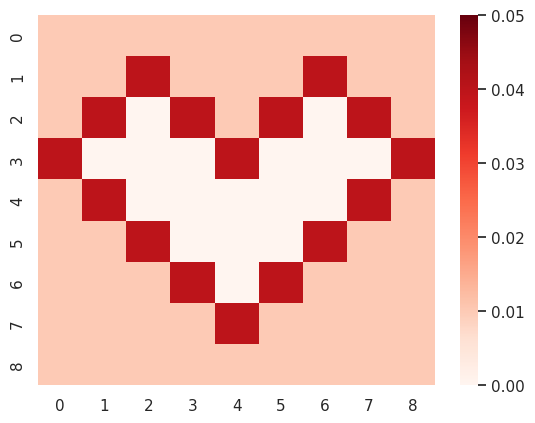

In [ ]:
# generate parameters and plot variance
mean, var = gen_parameters()
print("True data uncertainty (variance). The white region will not contain any traing data.")
sns.heatmap(var, cmap="Reds", vmax=0.05)

plt.show()

In [ ]:
# function for generating train and validation sets
def generate_training_data(n_samples, mean, var, num_cat=9, seed=0):
    np.random.seed(seed)
    train = []
    target = []
    val = []
    val_target = []
    for i in range(num_cat):
        for j in range(num_cat):
            if var[i, j] == 0:
                continue

            for _ in range(n_samples):
                train.append([i, j])
                val.append([i, j])
                target.append(np.random.normal(mean[i, j], math.sqrt(var[i, j])))
                val_target.append(np.random.normal(mean[i, j], math.sqrt(var[i, j])))

    train = np.asarray(train, dtype=np.float32)
    target = np.asarray(target, dtype=np.float32)

    return train, target, val, val_target

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor

import numpy as np
import warnings
warnings.filterwarnings(action='ignore')


class MyDecisionTreeRegressor(DecisionTreeRegressor):
    def __init__(
        self,
        criterion="squared_error",
        splitter="best",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,
        max_features=None,
        random_state=None,
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        ccp_alpha=0.0,
    ):

        self.node_stats = None  # new attribute to store node statistics

        super().__init__(
            criterion=criterion,
            splitter=splitter,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            min_weight_fraction_leaf=min_weight_fraction_leaf,
            max_features=max_features,
            max_leaf_nodes=max_leaf_nodes,
            random_state=random_state,
            min_impurity_decrease=min_impurity_decrease,
            ccp_alpha=ccp_alpha,
        )

    def fit(self, X, y, sample_weight=None, check_input=True):

        super().fit(
            X,
            y,
            sample_weight=sample_weight,
            check_input=check_input,
            )

        # compute node statistics and store in node_stats attribute
        self.node_stats = [self._compute_node_stats(X, y, node) for node in range(self.tree_.node_count)]

    def _compute_node_stats(self, X, y, node):
        mask = self.tree_.apply(X)
        node_mask = (mask == node)
        node_size = np.sum(node_mask)
        if node_size == 0:
            return None
        else:
            node_stats = {}
            node_stats['mean_feature_vector'] = np.mean(X[node_mask], axis=0)
            node_stats['mean_target_value'] = np.mean(y[node_mask])
            node_stats['var_target_value'] = np.var(y[node_mask])
            node_stats['node_size'] = node_size
            return node_stats

    def predict_var(self, X):
        node_idxs = self.tree_.apply(X)
        return np.array([self.node_stats[node_idx]['var_target_value'] for node_idx in node_idxs])

In [ ]:
class RandomForestUncertaintyEstimator(BaggingRegressor):
    def __init__(
        self,
        criterion="squared_error",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        ccp_alpha=0.0,
        n_estimators=10,
        max_samples=1.0,
        max_features=1.0,
        bootstrap=True,
        bootstrap_features=False,
        oob_score=False,
        warm_start=False,
        n_jobs=None,
        random_state=None,
        verbose=0,
    ):
        estimator = MyDecisionTreeRegressor(
            criterion=criterion,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            min_weight_fraction_leaf=min_weight_fraction_leaf,
            max_leaf_nodes=max_leaf_nodes,
            random_state=random_state,
            min_impurity_decrease=min_impurity_decrease,
            ccp_alpha=ccp_alpha,
        )

        super().__init__(
            estimator=estimator,
            n_estimators=n_estimators,
            max_samples=max_samples,
            max_features=max_features,
            bootstrap=bootstrap,
            bootstrap_features=bootstrap_features,
            oob_score=oob_score,
            warm_start=warm_start,
            n_jobs=n_jobs,
            random_state=random_state,
            verbose=verbose,
        )

        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_weight_fraction_leaf = min_weight_fraction_leaf
        self.max_features = max_features
        self.max_leaf_nodes = max_leaf_nodes
        self.min_impurity_decrease = min_impurity_decrease
        self.ccp_alpha = ccp_alpha

    def estimate_knowledge_uncertainty(self, X):
        return np.var([estimator.predict(X) for estimator in self.estimators_], axis=0)

    def estimate_data_uncertainty(self, X):
        return np.mean([estimator.predict_var(X) for estimator in self.estimators_], axis=0)

    def estimate_total_uncertainty(self, X):
        return self.estimate_knowledge_uncertainty(X=X) + self.estimate_data_uncertainty(X=X)

In [ ]:
num_cat = 9

# generate train and validation datasets
train, target, val, val_target = generate_training_data(n_samples=5_000, mean=mean, var=var, num_cat=9)

# generate test, consisting of all possible feature combinations
test = np.asarray([[i, j] for i in range(num_cat) for j in range(num_cat)], dtype=np.float32)

In [ ]:
estimator = RandomForestUncertaintyEstimator(
    n_estimators=10,
    # max_depth=7,
    min_samples_leaf=10,
    max_samples=0.5,
    random_state=3407,
    n_jobs=-1
)

estimator.fit(
    X=train,
    y=target
)

RandomForestUncertaintyEstimator(max_samples=0.5, min_samples_leaf=10,
                                 n_jobs=-1, random_state=3407)

In [ ]:
estimator.score(X=train, y=target)

0.8361378394908406

In [ ]:
estimator.score(X=val, y=val_target)

0.8363178059003878

Average predicted data uncertainty:


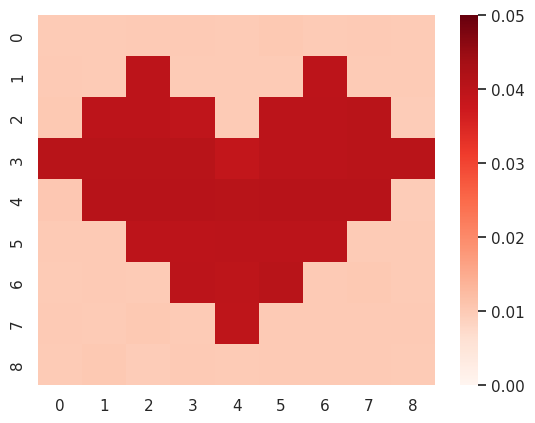

In [ ]:
data_uncertainty = estimator.estimate_data_uncertainty(X=test)

print("Average predicted data uncertainty:")            
sns.heatmap(data_uncertainty.reshape([num_cat, num_cat]), cmap="Reds", vmin=0, vmax=0.05)
plt.show()

Knowledge uncertainty via ensemble:


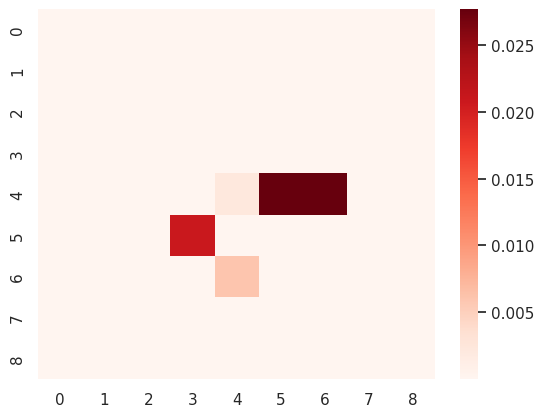

In [ ]:
knowledge_uncertainty = estimator.estimate_knowledge_uncertainty(X=test)

print("Knowledge uncertainty via ensemble:")            
sns.heatmap(knowledge_uncertainty.reshape([num_cat, num_cat]), cmap="Reds")
plt.show()

Total uncertainty via ensemble:


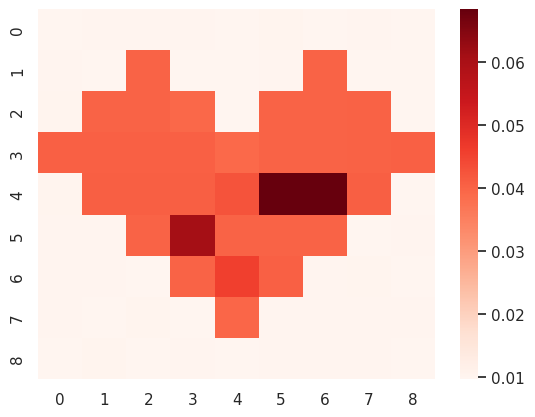

In [ ]:
total_uncertainty = estimator.estimate_total_uncertainty(X=test)

print("Total uncertainty via ensemble:")            
sns.heatmap(total_uncertainty.reshape([num_cat, num_cat]), cmap="Reds")
plt.show()

In [ ]:
def obj(x: np.ndarray):
    return np.sin(x)

def noise(x: np.ndarray):
    return np.abs(np.cos(x))

n_samples = 10_000

x = np.array([])
for loc in [-1.5*np.pi, -0.5*np.pi, 0.5*np.pi, 1.5*np.pi]:
    x = np.append(x, np.random.normal(loc=loc, scale=0.25*np.pi, size=2_500))

x = x.reshape((n_samples, 1)).astype(np.float32)

t = obj(x[:,0])
y = t + np.random.normal(scale=noise(x[:,0]), size=n_samples)

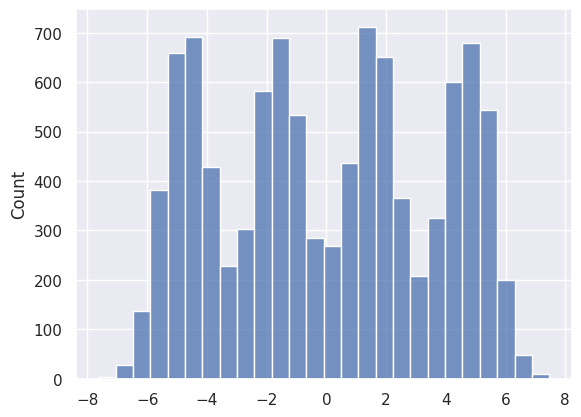

In [ ]:
sns.histplot(x=x[:, 0])

plt.grid(True)
plt.show()

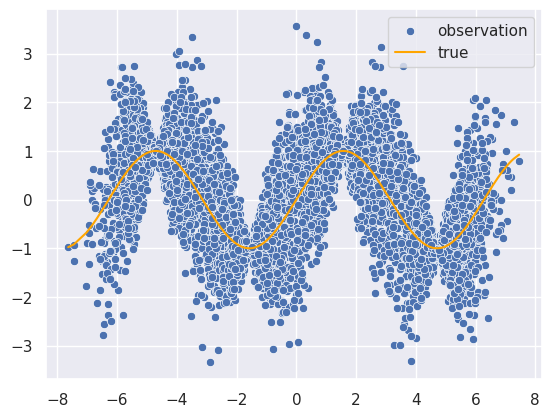

In [ ]:
sns.scatterplot(x=x[:, 0], y=y, label='observation')
sns.lineplot(x=x[:,0], y=t, color='orange', label='true')

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
estimator = RandomForestUncertaintyEstimator(
    n_estimators=100,
    max_depth=6,
    min_samples_leaf=10,
    max_samples=0.8,
    random_state=3407,
    n_jobs=-1
)

estimator.fit(
    X=x,
    y=y
)

RandomForestUncertaintyEstimator(max_depth=6, max_samples=0.8,
                                 min_samples_leaf=10, n_estimators=100,
                                 n_jobs=-1, random_state=3407)

In [ ]:
estimator.score(X=x, y=y)

0.655528511872123

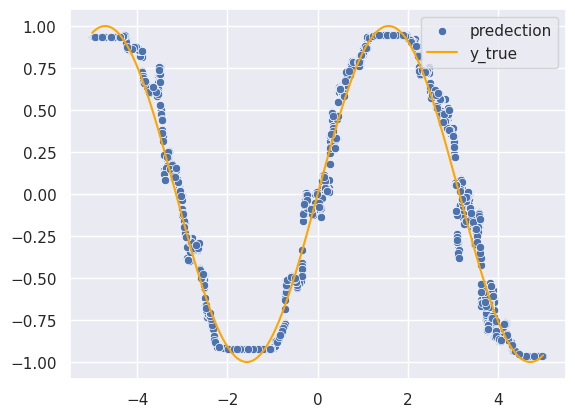

In [ ]:
X_test = np.random.uniform(-5, 5, n_samples).reshape((n_samples, 1)).astype(np.float32)
y_test = obj(X_test[:, 0])

sns.scatterplot(x=X_test[:, 0], y=estimator.predict(X_test), label='predection')
sns.lineplot(x=X_test[:,0], y=y_test, color='orange', label='y_true')

plt.legend()
plt.grid(True)
plt.show()

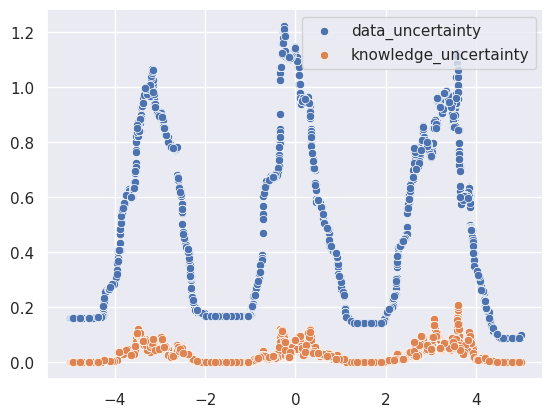

In [ ]:
sns.scatterplot(x=X_test[:, 0], y=estimator.estimate_data_uncertainty(X_test), label='data_uncertainty')
sns.scatterplot(x=X_test[:, 0], y=estimator.estimate_knowledge_uncertainty(X_test), label='knowledge_uncertainty')

plt.legend()
plt.grid(True)
plt.show()